
Running Cuckoo Search...


CLOUD COMPUTING EFFICIENCY: RESULTS
Tasks: 30 | Virtual machines: 5
Total workload: 1914 units

Metric                         Random baseline   Cuckoo Search
----------------------------------------------------------------
Estimated makespan                 405.00          360.00
Fitness (lower is better)           419.24          367.18
CPU utilization proxy (%)            82.91           93.27
VM load standard deviation           47.82           27.13

Estimated makespan improvement: 11.11%

Final VM loads:
VM 1: baseline load = 405.00, Cuckoo Search load = 356.00
VM 2: baseline load = 275.00, Cuckoo Search load = 360.00
VM 3: baseline load = 381.11, Cuckoo Search load = 357.78
VM 4: baseline load = 334.00, Cuckoo Search load = 288.00
VM 5: baseline load = 304.55, Cuckoo Search load = 338.18


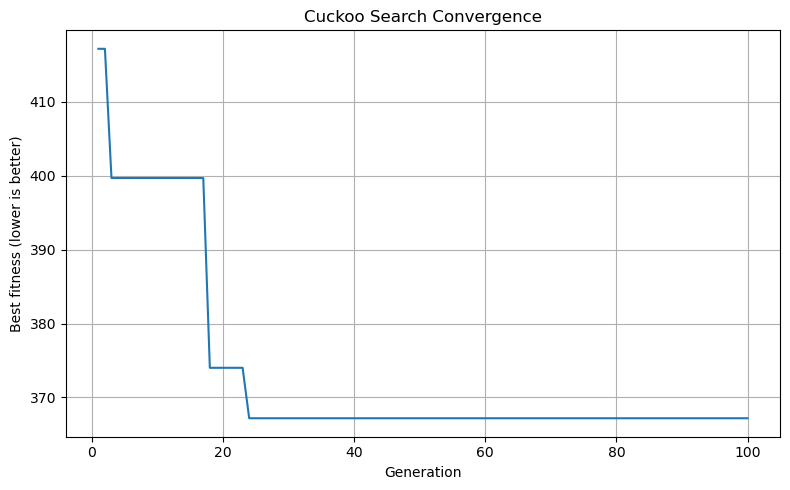

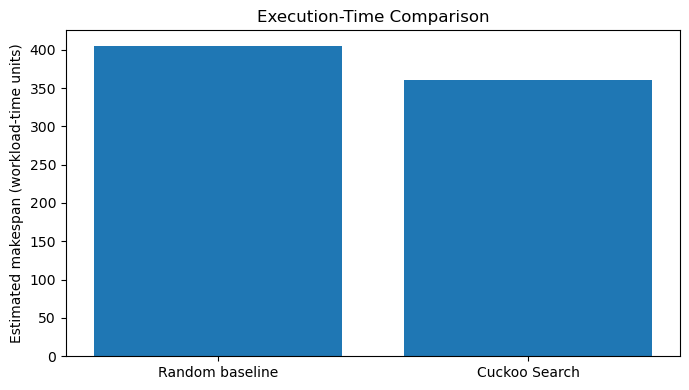

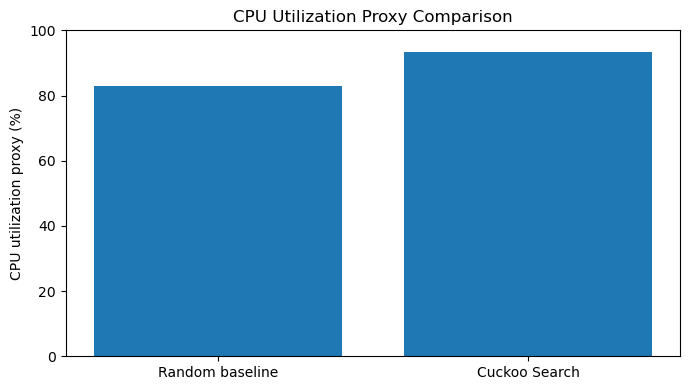

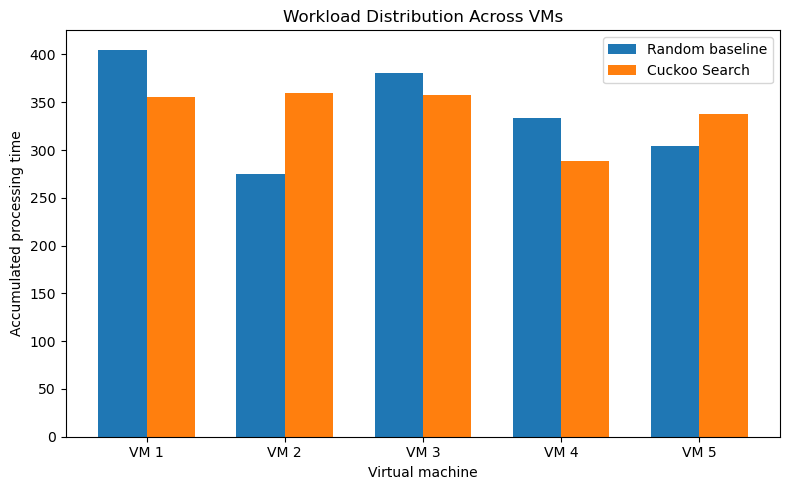

In [3]:
"""
Cuckoo Search for Cloud Computing Efficiency
Paper-aligned simulation based on:
"An Improved Cuckoo Search Algorithm for System Efficiency in Cloud Computing"

This is a simplified simulation, not an exact reproduction of the paper.
Requirements:
    python -m pip install numpy matplotlib
Run:
    python cuckoo_cloud_optimization.py
"""

import math
import numpy as np
import matplotlib.pyplot as plt


# -------------------- Configuration --------------------
RANDOM_SEED = 42
NUM_TASKS = 30
NUM_VMS = 5
POPULATION_SIZE = 25
MAX_GENERATIONS = 100
PA = 0.25                  # Fraction of nests to abandon
ALPHA = 0.15               # Lévy-flight step scale
BETA = 1.5                 # Lévy-flight exponent

rng = np.random.default_rng(RANDOM_SEED)

# Relative processing capacity of each virtual machine (VM).
# Larger value means that VM processes work faster.
VM_CAPACITY = np.array([1.0, 1.2, 0.9, 1.5, 1.1])

# Simulated task workloads; these are arbitrary workload units.
task_workloads = rng.integers(20, 101, size=NUM_TASKS).astype(float)


# -------------------- Evaluation / fitness --------------------
def decode_solution(solution):
    """Convert each task's encoded position into a VM number."""
    vm_indices = np.floor(solution * NUM_VMS).astype(int)
    return np.clip(vm_indices, 0, NUM_VMS - 1)


def evaluate(solution):
    """
    Return fitness, makespan, VM loads, and task assignments.
    Lower fitness is better.

    fitness = makespan * (1 + 0.25 * relative_load_imbalance)
    makespan is the largest accumulated processing time among VMs.
    """
    assignment = decode_solution(solution)
    vm_loads = np.zeros(NUM_VMS, dtype=float)

    for task_index, vm_index in enumerate(assignment):
        processing_time = task_workloads[task_index] / VM_CAPACITY[vm_index]
        vm_loads[vm_index] += processing_time

    makespan = float(np.max(vm_loads))
    mean_load = float(np.mean(vm_loads))
    imbalance = float(np.std(vm_loads) / (mean_load + 1e-9))
    fitness = makespan * (1.0 + 0.25 * imbalance)

    return fitness, makespan, vm_loads, assignment


# -------------------- Lévy-flight generation --------------------
def levy_flight(size, beta=BETA):
    """Generate random Lévy-flight steps using Mantegna's method."""
    numerator = (
        math.gamma(1 + beta) * math.sin(math.pi * beta / 2)
    )
    denominator = (
        math.gamma((1 + beta) / 2)
        * beta
        * 2 ** ((beta - 1) / 2)
    )
    sigma_u = (numerator / denominator) ** (1 / beta)

    u = rng.normal(0, sigma_u, size=size)
    v = rng.normal(0, 1, size=size)
    return u / (np.abs(v) ** (1 / beta) + 1e-12)


# -------------------- Cuckoo Search algorithm --------------------
def cuckoo_search():
    # Each nest represents one possible allocation of tasks to VMs.
    nests = rng.uniform(0, 1, size=(POPULATION_SIZE, NUM_TASKS))
    fitness = np.array([evaluate(nest)[0] for nest in nests])

    best_index = int(np.argmin(fitness))
    best_nest = nests[best_index].copy()
    best_fitness = float(fitness[best_index])
    history = []

    for generation in range(MAX_GENERATIONS):
        # Generate new solutions by Lévy-flight movement.
        for i in range(POPULATION_SIZE):
            candidate = nests[i] + ALPHA * levy_flight(NUM_TASKS)
            candidate = np.clip(candidate, 0, 1)
            candidate_fitness = evaluate(candidate)[0]

            # Compare candidate against a randomly selected nest.
            j = int(rng.integers(0, POPULATION_SIZE))
            if candidate_fitness < fitness[j]:
                nests[j] = candidate
                fitness[j] = candidate_fitness

        # Abandon the worst nests and replace them with random solutions.
        number_to_abandon = max(1, int(PA * POPULATION_SIZE))
        worst_indices = np.argsort(fitness)[-number_to_abandon:]
        nests[worst_indices] = rng.uniform(
            0, 1, size=(number_to_abandon, NUM_TASKS)
        )
        fitness[worst_indices] = np.array(
            [evaluate(nest)[0] for nest in nests[worst_indices]]
        )

        # Track the best solution found so far.
        current_best_index = int(np.argmin(fitness))
        if fitness[current_best_index] < best_fitness:
            best_fitness = float(fitness[current_best_index])
            best_nest = nests[current_best_index].copy()

        history.append(best_fitness)

        

    return best_nest, history


# -------------------- Baseline and optimization --------------------
def main():
    # Baseline: assign tasks randomly once.
    baseline_solution = rng.uniform(0, 1, size=NUM_TASKS)
    base_fitness, base_makespan, base_loads, _ = evaluate(baseline_solution)

    print("\nRunning Cuckoo Search...\n")
    best_solution, fitness_history = cuckoo_search()
    cs_fitness, cs_makespan, cs_loads, cs_assignment = evaluate(best_solution)

    # A simple aggregate utilization proxy for this simulated workload.
    # It is not a real operating-system/cloud CPU measurement.
    total_work = float(np.sum(task_workloads))
    total_capacity = float(np.sum(VM_CAPACITY))
    base_utilization = min(
        100.0, total_work / (base_makespan * total_capacity) * 100
    )
    cs_utilization = min(
        100.0, total_work / (cs_makespan * total_capacity) * 100
    )

    improvement = (
        (base_makespan - cs_makespan) / base_makespan * 100
        if base_makespan > 0 else 0.0
    )

    print("\n" + "=" * 64)
    print("CLOUD COMPUTING EFFICIENCY: RESULTS")
    print("=" * 64)
    print(f"Tasks: {NUM_TASKS} | Virtual machines: {NUM_VMS}")
    print(f"Total workload: {total_work:.0f} units")
    print("\nMetric                         Random baseline   Cuckoo Search")
    print("-" * 64)
    print(f"Estimated makespan             {base_makespan:10.2f}   {cs_makespan:13.2f}")
    print(f"Fitness (lower is better)       {base_fitness:10.2f}   {cs_fitness:13.2f}")
    print(f"CPU utilization proxy (%)       {base_utilization:10.2f}   {cs_utilization:13.2f}")
    print(f"VM load standard deviation      {np.std(base_loads):10.2f}   {np.std(cs_loads):13.2f}")
    print(f"\nEstimated makespan improvement: {improvement:.2f}%")

    print("\nFinal VM loads:")
    for vm_index in range(NUM_VMS):
        print(
            f"VM {vm_index + 1}: baseline load = {base_loads[vm_index]:.2f}, "
            f"Cuckoo Search load = {cs_loads[vm_index]:.2f}"
        )

    # Graph 1: convergence of best fitness.
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, MAX_GENERATIONS + 1), fitness_history)
    plt.xlabel("Generation")
    plt.ylabel("Best fitness (lower is better)")
    plt.title("Cuckoo Search Convergence")
    plt.grid(True)
    plt.tight_layout()

    # Graph 2: estimated makespan comparison.
    plt.figure(figsize=(7, 4))
    plt.bar(["Random baseline", "Cuckoo Search"], [base_makespan, cs_makespan])
    plt.ylabel("Estimated makespan (workload-time units)")
    plt.title("Execution-Time Comparison")
    plt.tight_layout()

    # Graph 3: CPU utilization proxy comparison.
    plt.figure(figsize=(7, 4))
    plt.bar(
        ["Random baseline", "Cuckoo Search"],
        [base_utilization, cs_utilization],
    )
    plt.ylabel("CPU utilization proxy (%)")
    plt.title("CPU Utilization Proxy Comparison")
    plt.ylim(0, 100)
    plt.tight_layout()

    # Graph 4: VM workload balance comparison.
    x = np.arange(NUM_VMS)
    width = 0.35
    plt.figure(figsize=(8, 5))
    plt.bar(x - width / 2, base_loads, width, label="Random baseline")
    plt.bar(x + width / 2, cs_loads, width, label="Cuckoo Search")
    plt.xlabel("Virtual machine")
    plt.ylabel("Accumulated processing time")
    plt.title("Workload Distribution Across VMs")
    plt.xticks(x, [f"VM {i + 1}" for i in range(NUM_VMS)])
    plt.legend()
    plt.tight_layout()

    plt.show()


if __name__ == "__main__":
    main()
